# EDA Individual Samuel — Keragaman token dan indikasi artefak

**KASDAD TP2 · A06 KasdudLovers · SamuelIndriano · 2406400524**

## 1. Pertanyaan dan konteks

**Pada laporan dengan jumlah token yang sama, apakah keragaman token dalam
`signal_stream` berkaitan dengan proporsi `artifact_signal = 1` yang teramati?**

Dataset Cyber Vulnerability Lifecycle memuat observasi kerentanan pada cycle disclosure
berurutan. `signal_stream` adalah deretan token teknis anonim dari narasi yang dapat
kosong dan mengandung noise (PDF resmi, p.16). `artifact_signal` bernilai 0/1 untuk
indikasi artefak eksploit publik; label 0 berarti tidak teramati, bukan terbukti tidak ada.
Makna target mengikuti [informasi kompetisi](../../docs/COMPETITION_INFO.md),
terpisah dari deskripsi fitur pada PDF.

Dua laporan dapat sama panjang tetapi mempunyai repetisi berbeda. Saya mendefinisikan
**TTR = jumlah token unik / jumlah token total**, dengan regex `[A-Za-z0-9]+` dan lowercase,
sama seperti discovery. Contoh ilustratif, bukan data: `a a b b` mempunyai TTR 2/4,
sedangkan `a b c d` mempunyai TTR 4/4. TTR mengukur keragaman/repetisi token;
ia tidak langsung mengukur kualitas teks, makna semantik, atau tingkat bahaya.

Pertanyaan ini resmi dipilih pada 31 Oktober 2026. EDA temporal impact–threat sebelumnya
tetap disimpan sebagai arsip penelitian, dan tidak menjadi pertanyaan utama notebook ini.

## 2. Data dan persiapan

Perhitungan menggunakan **official Classification Train saja**. Tidak ada label Test,
pseudo-label, cache pribadi, training model atau Kaggle upload. Semua angka EDA utama
di bawah dihitung ulang pada eksekusi ini; laporan discovery/robustness hanya referensi.

Pasang dependensi `requirements.txt`. Data default: `data/raw/classification/Train.csv`;
alternatif `TP2_DATA_DIR` menunjuk folder induk `classification/`. Jalankan dari dalam
repository agar fungsi analisis di `src/` dan helper riset di `scripts/` tersedia.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT=Path.cwd().resolve()
while not (ROOT/'src/utils/paths.py').exists() and ROOT!=ROOT.parent: ROOT=ROOT.parent
if not (ROOT/'src/utils/paths.py').exists(): raise FileNotFoundError('Buka notebook dari dalam repository TP2.')
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.utils.paths import task_files
from src.data.samuel_eda_a import (derive_features, exact_length_comparison,
    period_comparison, exact_cycle_comparison)
from src.data.samuel_eda_a_figures import (overview_figure, primary_figure,
    period_figure, cycle_figure)
get_ipython().run_line_magic('matplotlib','inline')
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False,
                     'figure.facecolor':'white'})
pd.set_option('display.precision',4)
OUTPUT=ROOT/'reports/eda_a_formal'
(OUTPUT/'figures').mkdir(parents=True,exist_ok=True)
def show(fig,name):
    fig.savefig(OUTPUT/'figures'/name,dpi=160,bbox_inches='tight')
    display(fig)
    plt.close(fig)

In [2]:
source=task_files('classification')['train']
if source is None: raise FileNotFoundError('Official Classification Train.csv tidak ditemukan.')
input_sha=hashlib.sha256(source.read_bytes()).hexdigest()
assert input_sha=='875552a68a3d24b0f3e1966d6ddb5671e6f54305a1c526e2f0a76747942ed91c'
train=pd.read_csv(source)
assert train.shape==(50608,19) and train.record_id.is_unique
assert train.artifact_signal.isin([0,1]).all() and train.cycle_code.between(47,79).all()
derived=derive_features(train)
present=derived.loc[~derived.stream_missing & derived.token_count.gt(0)].copy()
availability=pd.DataFrame({'populasi':['Seluruh Train','Stream tersedia','Stream kosong/blank'],
    'n':[len(derived),len(present),int(derived.stream_missing.sum())]})
availability['persentase Train']=100*availability.n/len(derived)
labels=train.artifact_signal.value_counts().sort_index().rename_axis('artifact_signal').to_frame('n')
labels['persentase Train']=100*labels.n/len(train)
display(availability.round(2)); display(labels.round(2))
display(present[['token_count','ttr']].quantile([0,.25,.5,.75,1]).rename_axis('kuantil'))
assert len(present)==47204 and int(derived.stream_missing.sum())==3404

,populasi,n,persentase Train
0,Seluruh Train,50608,100.00
1,Stream tersedia,47204,93.27
2,Stream kosong/blank,3404,6.73


,n,persentase Train
artifact_signal,,
0,33038,65.28
1,17570,34.72


,token_count,ttr
kuantil,,
0.00,8.0,0.0809
0.25,22.0,0.7846
0.50,34.0,0.8750
0.75,52.0,0.9444
1.00,145.0,1.0000


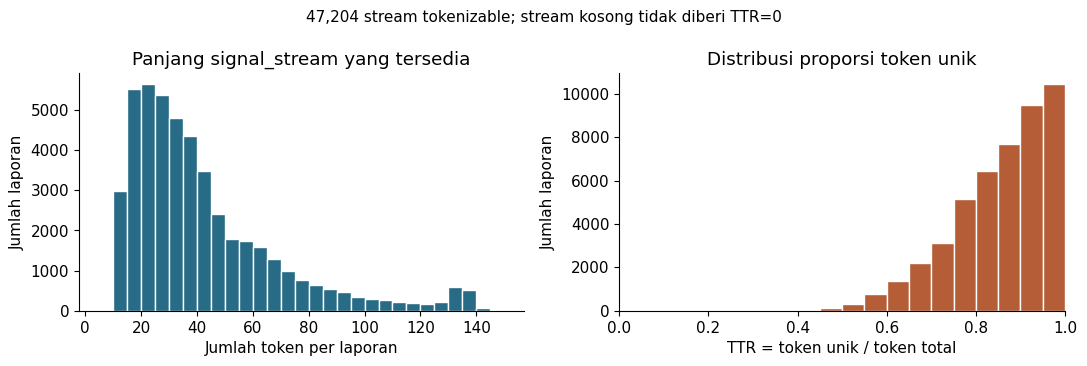

In [3]:
show(overview_figure(derived),'01_data_overview.png')

Train berisi 50.608 observasi; 47.204 stream dapat dianalisis dan 3.404 (6,73%) kosong.
Kelas 0 lebih banyak daripada kelas 1. Stream kosong tidak diberi TTR=0 karena ketiadaan
teks berbeda dari keragaman rendah. Pada data ini tidak ada stream nonblank tanpa token.
Histogram memberi konteks support; ia belum menjawab hubungan TTR dengan artifact.

## 3. Analisis utama: perbandingan pada jumlah token yang sama

Rasio keragaman dipengaruhi panjang teks, sehingga perbandingan dilakukan pada setiap
**exact token count**. Di dalam panjang yang sama, hitung posisi rata-rata nilai TTR
yang terurut, lalu bagi dengan n. Ties mendapat average percentile rank yang sama;
tidak dipisah secara arbitrer. Grup rendah memiliki rank≤0,25, grup tinggi rank≥0,75.

Panjang harus mempunyai **n≥120**, variasi TTR, serta **≥20 baris di setiap grup**.
Kedua grup menggunakan bobot panjang yang sama, `n_panjang / total n_support`.
Hasil adalah rata-rata proporsi per panjang dengan komposisi panjang dibuat sama,
bukan proporsi mentah dari seluruh tail yang digabungkan.

,panjang didukung,baris support,coverage stream tersedia (%),coverage semua Train (%),panjang positif,panjang negatif
0,71,37681,79.83,74.46,64,7


,grup,n yang dibandingkan,artifact=1 tertimbang (%)
0,Keragaman rendah,9011,24.19
1,Keragaman tinggi,9354,38.39


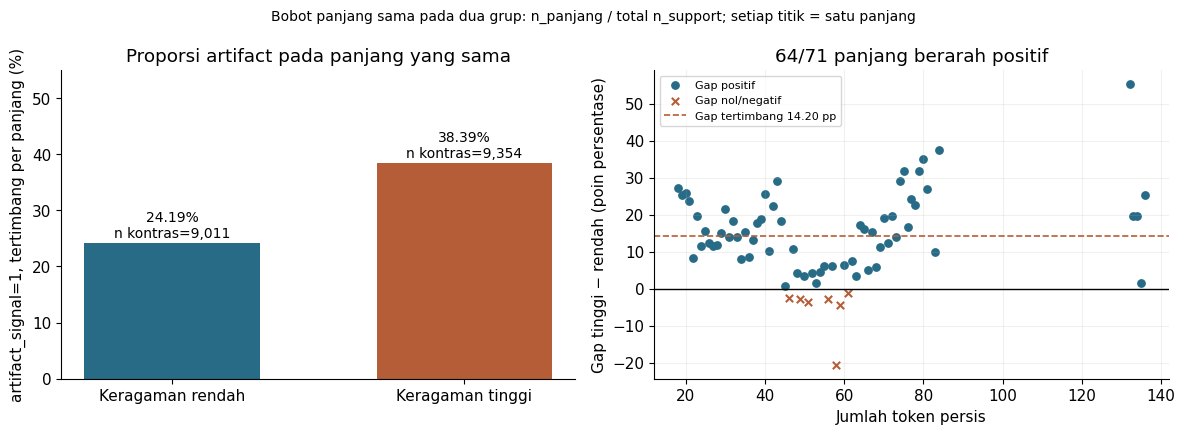

In [4]:
primary_by_length,primary=exact_length_comparison(derived,min_rows=120,min_tail=20)
support=pd.DataFrame([{
    'panjang didukung':primary['strata'],'baris support':primary['support_rows'],
    'coverage stream tersedia (%)':100*primary['coverage_present'],
    'coverage semua Train (%)':100*primary['coverage_all_rows'],
    'panjang positif':primary['positive_strata'],'panjang negatif':primary['negative_strata']}])
comparison=pd.DataFrame({'grup':['Keragaman rendah','Keragaman tinggi'],
    'n yang dibandingkan':[primary['low_n'],primary['high_n']],
    'artifact=1 tertimbang (%)':[100*primary['low_rate'],100*primary['high_rate']]})
display(support.round(2));display(comparison.round(2))
assert primary['strata']==71 and primary['support_rows']==37681
assert (primary['low_n'],primary['high_n'])==(9011,9354)
assert np.isclose(primary['delta'],.14201954123205932,atol=1e-12,rtol=0)
show(primary_figure(primary_by_length,primary),'02_exact_length_primary.png')

**Jawaban awal:** pada common support yang diuji, proporsi artifact=1 lebih tinggi
pada grup dengan keragaman token tinggi: **38,39% versus 24,19%**, gap **+14,20 poin
persentase**. Sebanyak 64/71 panjang searah; tujuh panjang berlawanan arah tetap ditampilkan.

Denominator perlu dibedakan: **37.681** adalah seluruh baris pada panjang yang didukung,
sedangkan kontras memakai **9.011 rendah + 9.354 tinggi**. Baris di tengah ikut menentukan
bobot support tetapi tidak dibandingkan sebagai tail. Coverage 79,83% stream tersedia
atau 74,46% semua Train; hasil ini tidak mewakili seluruh panjang atau stream kosong.
Ukuran tail bukan penyebut langsung dari persentase tertimbang: setiap panjang
menyumbang proporsi dengan bobot yang sama untuk kedua grup.

## 4. Robustness terhadap waktu

Prevalence artifact dan komposisi laporan dapat berbeda antar-cycle. Saya mempertahankan
exact length, lalu membentuk tiga periode 11 cycle tanpa memotong cycle. Rank TTR
dihitung ulang **di dalam exact length × periode**, dengan aturan120/20 yang sama.
Ini bukan analisis tren impact–threat seperti EDA lama.

,cycle,stream tersedia,baris support,coverage (%),n rendah,n tinggi,gap (pp),strata +/−
0,47–57,12537,8284,66.08,1810,2074,5.65,23/10
1,58–68,15664,9621,61.42,2336,2454,15.19,27/6
2,69–79,19003,13717,72.18,3239,3671,13.82,37/14


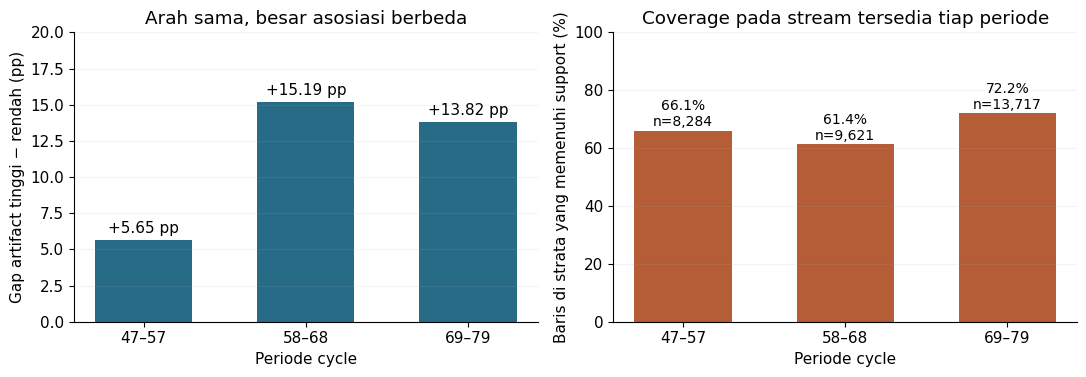

In [5]:
period_cells,temporal=period_comparison(derived,min_rows=120,min_tail=20)
period_table=pd.DataFrame([{
    'cycle':r['period'],'stream tersedia':r['denominator_present'],
    'baris support':r['support_rows'],'coverage (%)':100*r['coverage_present'],
    'n rendah':r['low_n'],'n tinggi':r['high_n'],
    'gap (pp)':100*r['delta'],'strata +/−':f"{r['positive_strata']}/{r['negative_strata']}"}
    for r in temporal['periods']])
display(period_table.round(2))
assert np.isclose(temporal['pooled']['delta'],.12096638032779648,atol=1e-12,rtol=0)
show(period_figure(temporal),'03_period_robustness.png')

Ketiga periode positif, tetapi magnitude berbeda: **+5,65/+15,19/+13,82 pp**.
Pooled supported-strata contrast **+12,10 pp**, dengan 31.622 support rows (67,0%
stream tersedia); kontras memakai 7.385 rendah dan 8.199 tinggi. Periode awal lebih lemah,
sehingga pola tidak boleh disebut seragam sepanjang waktu.

Perubahan 14,20→12,10 bukan dekomposisi efek cycle murni: support dan rank lokal ikut
berubah. Sensitivitas support60/10 dan common-length weighting yang sudah diverifikasi
tersimpan pada [laporan robustness](../../reports/eda_a_robustness/FINDINGS.md).

### Exact length × exact cycle: estimand tambahan

Tiga periode masih menyisakan perbedaan antarsiklus. Pemeriksaan tambahan memusatkan
TTR dan label pada mean **setiap exact length×cycle cell**, kemudian merangkum hubungan
linear within-cell. Syaratnya n≥5 dan sedikitnya dua nilai TTR berbeda; sel dengan label
konstan tetap dipakai. Bobot berasal dari variasi TTR dalam sel, bukan bobot panjang
pada analisis tail. Karena itu **koefisien linear bukan high-versus-low prevalence gap**.

,sel didukung,baris support,coverage stream tersedia (%),"koefisien (pp per +0,10 TTR)",cycle positif
0,2246,43333,91.8,7.99,31


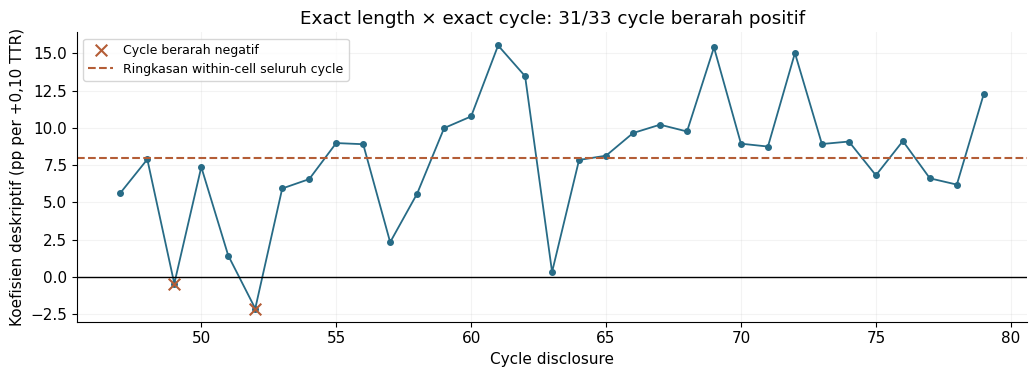

In [6]:
exact_cells,within,cycles=exact_cycle_comparison(derived,min_n=5)
display(pd.DataFrame([{
    'sel didukung':within['eligible_cells'],'baris support':within['eligible_support_rows'],
    'coverage stream tersedia (%)':100*within['coverage_of_nonblank_rows'],
    'koefisien (pp per +0,10 TTR)':100*within['common_within_cell_slope_per_0_1_ttr'],
    'cycle positif':within['cycle_concentration']['positive_cycle_slopes']}]).round(2))
assert within['eligible_support_rows']==43333
assert np.isclose(within['common_within_cell_slope_per_0_1_ttr'],.07988321635749253,atol=1e-12,rtol=0)
assert within['cycle_concentration']['positive_cycle_slopes']==31
show(cycle_figure(cycles,within),'04_exact_cycle_robustness.png')

Ringkasan within-cell **+7,99 pp per +0,10 TTR**, mencakup **43.333 baris atau 91,80%
stream tersedia**. Arah positif pada 31/33 cycle; cycle 49 dan 52 menjadi counterexample.
Ini merangkum kemiringan linear bersama pada support yang berbeda, bukan menyatakan
setiap kenaikan TTR pasti mengubah label atau bahwa gap 14,20 berlaku pada setiap cycle.
Confounding kategori/konteks lain masih mungkin; coverage tinggi tidak menyamakannya
dengan estimand analisis utama.

## 5. Interpretasi dan relevansi

**Pertanyaan utama terjawab secara deskriptif:** pada data yang memenuhi dukungan,
laporan dengan keragaman token lebih tinggi cenderung mempunyai proporsi artifact=1
lebih tinggi meskipun jumlah token dibuat sama. Arah ini bertahan pada pemeriksaan
waktu, dengan besar asosiasi dan beberapa kelompok yang berbeda arah.

Batas yang harus dipertahankan:

- Token anonim tidak mengidentifikasi makna semantik atau kualitas laporan.
- Asosiasi tidak membuktikan bahwa keragaman token menyebabkan artifact.
- Exact length dan cycle tidak menghilangkan seluruh confounding.
- Stream kosong dan kelompok tanpa support berada di luar klaim utama.
- Train sudah digunakan untuk discovery; sensitivitas ini bukan validasi independen.
- Hubungan yang sama pada official Test belum dapat dijamin.

**Kaitan dengan Classification:** karakteristik teks berasosiasi dengan target,
sehingga representasi teks patut dipertimbangkan. Dalam eksperimen terpisah,
penambahan blok TF-IDF **beserta indikator missing-stream** pada structured Logistic
Regression memberi primary Macro F1 sekitar 0,7145→0,8206
([Round1 findings](../../reports/classification_round1/FINDINGS.md)). Itu evidence
prediktif dari evaluasi model, bukan hasil pengujian TTR di notebook ini. Ia tidak
membuktikan TTR menyebabkan kenaikan F1 atau merupakan fitur terbaik. Tidak ada model
yang dilatih atau diubah dalam EDA ini.

## 6. Kesimpulan

Keragaman token mempunyai asosiasi positif yang teramati dengan indikasi artifact
pada laporan dengan jumlah token sama: gap utama 14,20 pp, dengan mayoritas panjang
didukung searah. Pemeriksaan periode dan exact cycle mendukung arah tersebut sambil
menunjukkan heterogenitas. Kesimpulan dibatasi pada support Train yang dianalisis,
tanpa klaim sebab-akibat, semantik, kualitas teks, atau generalisasi Test.

Bukti penelitian lengkap tetap tersedia pada [discovery](../../reports/eda_candidates/DISCOVERY_FINDINGS.md)
dan [targeted robustness](../../reports/eda_a_robustness/FINDINGS.md).
[EDA temporal03](03_samuel_formal_eda.ipynb) dipertahankan sebagai arsip.
[Ringkasan, compliance dan reproduksi](../../reports/eda_a_formal/SUMMARY.md)
mencatat batas milestone EDA ini; finalisasi notebook modeling tidak dilanjutkan.

In [7]:
# Simpan hanya hasil agregat baru; tidak memanggil report writer historis.
primary_by_length.to_csv(OUTPUT/'primary_by_length.csv',index=False)
period_table.to_csv(OUTPUT/'period_summary.csv',index=False)
cycles.to_csv(OUTPUT/'cycle_summary.csv',index=False)
results={'question':'Pada laporan dengan jumlah token yang sama, apakah keragaman token dalam "signal_stream" berkaitan dengan proporsi "artifact_signal = 1" yang teramati?',
    'input_sha256':input_sha,'python':platform.python_version(),
    'rows':len(train),'stream_present':len(present),'stream_missing':int(derived.stream_missing.sum()),
    'label_counts':{str(k):int(v)for k,v in train.artifact_signal.value_counts().sort_index().items()},
    'length_and_ttr_quantiles':{col:{str(q):float(v)for q,v in present[col].quantile([0,.25,.5,.75,1]).items()}for col in ['token_count','ttr']},
    'primary':primary,'periods':temporal,'exact_cycle':within,
    'model_training_performed':False,'test_data_used':False}
(OUTPUT/'results.json').write_text(json.dumps(results,ensure_ascii=False,indent=2,allow_nan=False)+'\n',encoding='utf-8')
print('Hasil dihitung ulang dari official Train dan disimpan sebagai agregat. Empat grafik ditampilkan tanpa cache privat.')

Hasil dihitung ulang dari official Train dan disimpan sebagai agregat. Empat grafik ditampilkan tanpa cache privat.
